# Metamodel validation (propagation holdout)

Three steps:

1. **Fit** — `mm.fit(goal)` or `mm.fit_all()`
2. **Validate** — `val.sweep(goal)` for metrics; `val.validate(goal, n=…)` for plotting
3. **Plot** — `result.plot('10m')`, `result.plot_all()`, …

Validation loads saved models only (no refitting). Holdout metrics and plots
include **`hs`, `tp`, `dir`, `spr`** (`spr` via PCA; `tp` raw). Use
`mm.report_training_data(goal, n=450)` or `mm.load_fit_summary(goal, 450)` after
fit to inspect site filter and PCA site retention.

In [1]:
import matplotlib.pyplot as plt
from utils.config import METAMODEL, load_goals, mda_max_points
from utils import validation as val


In [2]:
goals = list(load_goals().keys())
candidates = METAMODEL["mda_candidates"]
metrics = METAMODEL["validation"]["metrics_variables"]
site_filter = METAMODEL["site_filter"]

print(f"goals      : {goals}")
print(f"candidates : {candidates}")
print(f"metrics    : {metrics}")
print(f"MDA max    : {mda_max_points()} (test cases = 500 - max)")
for key, threshold in site_filter.items():
    if key.endswith("_max"):
        var = key[:-4]
        print(f"{var} filter : > {threshold} removed before PCA (site_filter)")
    elif key.endswith("_min"):
        var = key[:-4]
        print(f"{var} filter : < {threshold} removed before PCA (site_filter)")
print("PCA NaN    : dry-site handling in metamodel.pca_preprocessing (see README)")

goals      : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16']
candidates : [50, 100, 150, 250, 450]
metrics    : ['hs', 'tp', 'dir', 'spr']
MDA max    : 450 (test cases = 500 - max)
hs filter : > 10.0 removed before PCA (site_filter)
tp filter : < 0.5 removed before PCA (site_filter)
PCA NaN    : dry-site handling in metamodel.pca_preprocessing (see README)


## 1 · Fit

In [3]:
# All goals:
# mm.fit_all(gp_epochs=1500)

## 2 · Validate

In [4]:
# Metrics for every MDA size → outputs/goal_01/validation_metrics.csv
metrics = val.sweep(7)
metrics.head()

,goal,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,7,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,hs,Hs,4250,-2.718608e-03,0.123028,0.387401,Metamodel,SnapWave
1,7,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,tp,Tp,4250,-4.298348e-08,0.000001,1.000000,Metamodel,SnapWave
2,7,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,dir,Dir,4250,3.005066e+00,14.945513,0.931725,Metamodel,SnapWave
3,7,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,spr,Spr,4250,-9.562686e-01,7.435092,0.686462,Metamodel,SnapWave
4,7,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,hs,Hs,4250,1.407650e-03,0.060092,0.864737,Metamodel,SnapWave


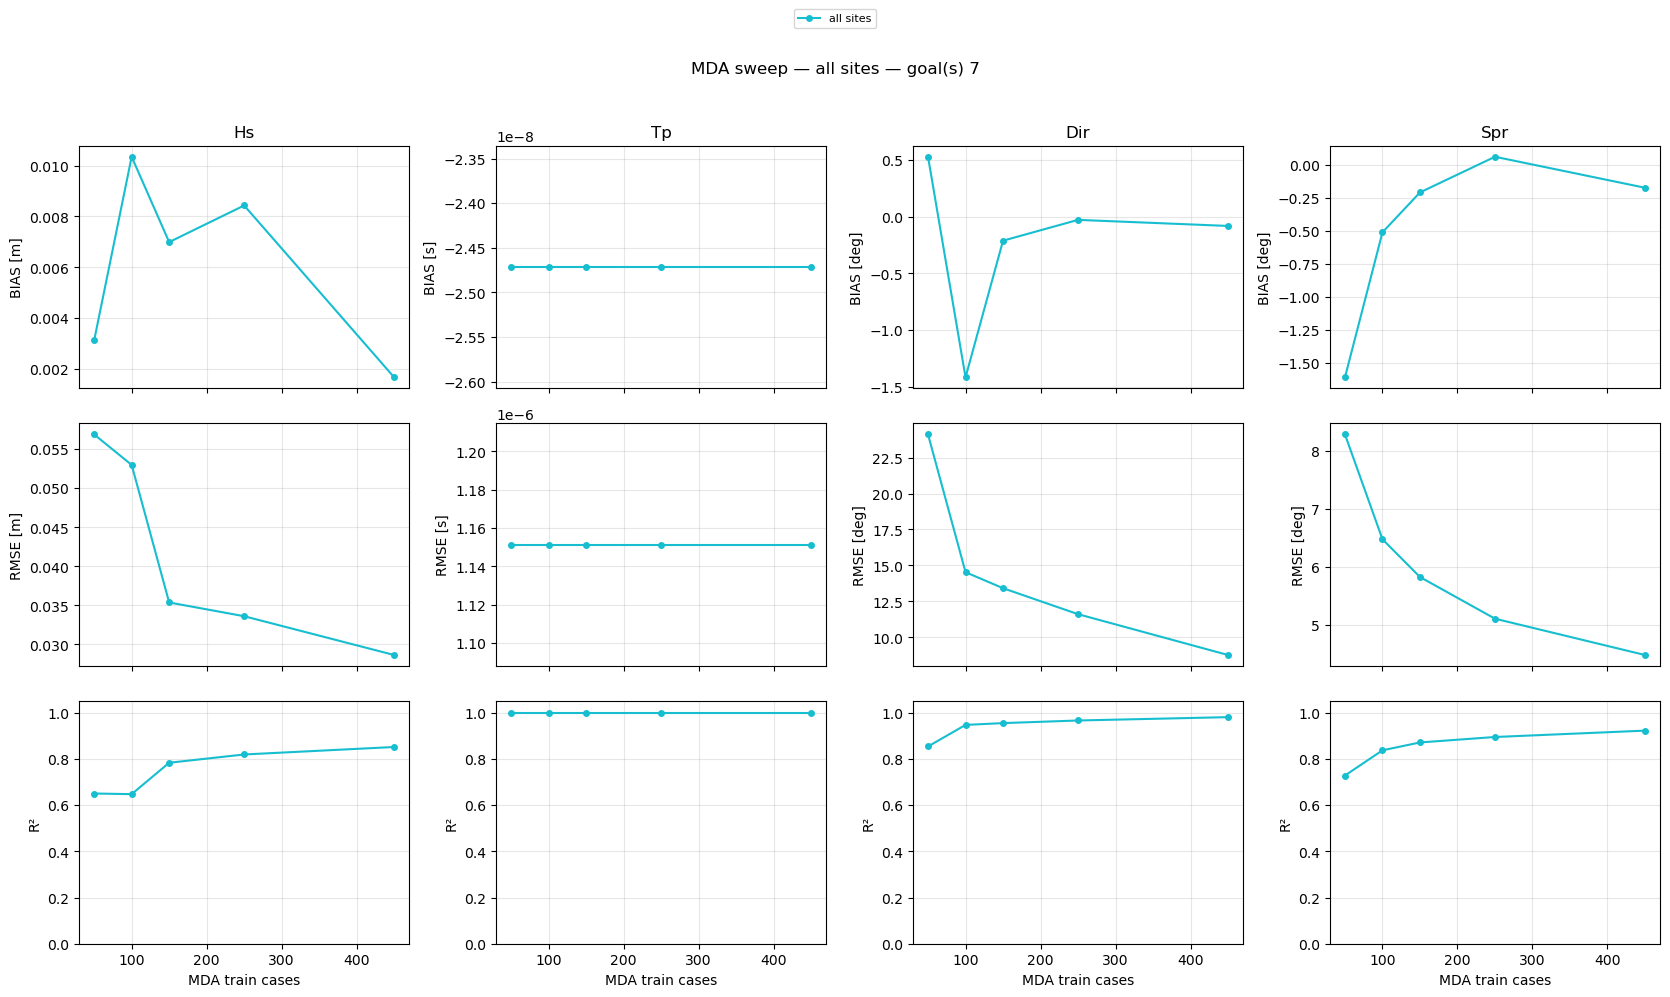

In [5]:
val.plot_sweep(metrics, by="bulk")
plt.show()

## 3 · Plot

In [6]:
n = 450  # MDA size to plot
result = val.validate(7, n)

# Available groups: isobath depths, mesh labels, buoy ids
[g[0] for g in val.metric_groups(result.estimate)]

['5m',
 '10m',
 '20m',
 '50m',
 'Apia',
 'buoy_Apolima_Buoy',
 'buoy_American_Samoa_Buoy',
 'buoy_Aunuu_Buoy']

In [7]:
# Map only, or scatters only
# result.plot_map("10m")
# result.plot_scatter("10m", variables=["hs"])

# All groups (optionally filter variables or groups)
for fig in result.plot_all(groups="waves", reference_label="buoy_Aunuu_Buoy"):
    plt.show()

## All goals

In [8]:
all_metrics = val.sweep_all()
all_metrics

,goal,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,hs,Hs,4200,-7.397800e-03,0.052793,0.831766,Metamodel,SnapWave
1,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,tp,Tp,4200,4.795242e-09,0.000001,1.000000,Metamodel,SnapWave
2,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,dir,Dir,4200,3.781980e-01,18.273926,0.897795,Metamodel,SnapWave
3,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,spr,Spr,4200,-5.084026e-01,10.020276,0.518574,Metamodel,SnapWave
4,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,hs,Hs,4250,-9.075145e-03,0.054644,0.828497,Metamodel,SnapWave
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2555,16,450,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_American_Samoa_Buoy,buoy,waves,spr,Spr,50,3.354807e-01,7.922446,0.743036,Metamodel,SnapWave
2556,16,450,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,hs,Hs,50,-3.456145e-04,0.017270,0.891139,Metamodel,SnapWave
2557,16,450,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,tp,Tp,50,2.430133e-07,0.000001,1.000000,Metamodel,SnapWave
2558,16,450,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,dir,Dir,50,-1.455951e+00,12.339387,0.965430,Metamodel,SnapWave


In [9]:
# Best MDA size per goal (10m isobath, Hs)
hs_10m = all_metrics.query("site_label == '10m' and variable == 'hs'")
best = hs_10m.loc[hs_10m.groupby("goal")["rmse"].idxmin()]
best[["goal", "mda_candidate", "site_label", "rmse", "r2", "n"]]

,goal,mda_candidate,site_label,rmse,r2,n
132,1,450,10m,0.026184,0.968491,4250
1572,10,450,10m,0.031860,0.958974,4250
1732,11,450,10m,0.025954,0.964826,4250
1892,12,450,10m,0.032149,0.972421,4250
2052,13,450,10m,0.043522,0.955386,4200
2212,14,450,10m,0.043522,0.963635,4250
2372,15,450,10m,0.035421,0.969453,4250
2532,16,450,10m,0.041700,0.942222,4250
292,2,450,10m,0.039143,0.948210,4250
452,3,450,10m,0.043364,0.964783,4250
